# LoTiC on Rotated MNIST

This notebook trains LoTiC from official pretrained backbones, evaluates every unseen
future domain, and saves the checkpoints and records produced by the run.

## Configuration

In [1]:
from pathlib import Path
import json, os, pickle, platform, random, time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from IPython.display import display
from transformers import AutoModel
from transformers.utils import logging as transformers_logging

transformers_logging.disable_progress_bar()

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

DATA_PATH = ROOT / "data" / "mnist.pkl"
CHECKPOINT_DIR = ROOT / "checkpoints"
RECORD_DIR = ROOT / "records"
CHECKPOINT_DIR.mkdir(exist_ok=True)
RECORD_DIR.mkdir(exist_ok=True)

requested = os.environ.get("LOTIC_BACKBONES", "dinov2b,dinov2l")
BACKBONES = [name.strip() for name in requested.split(",") if name.strip()]
SEED = 43
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
N_TRAIN, N_TEST, NUM_CLASSES = 15, 5, 10
RES, CHUNK = 112, 100
RANK, ALPHA = 8, 64.0
EPOCHS, LR = 300, 1e-3
PCT_START, WD, CLIP, DROP_PATH, PRINT_EVERY = 0.3, 1e-4, 1.0, 0.1, 10
TARGETS = ("attention.query", "attention.key", "attention.value")
CFG = {
    "dinov2b": {
        "model": "facebook/dinov2-base",
        "name": "DINOv2-B",
        "size": "86M",
        "file": "dinov2_b",
    },
    "dinov2l": {
        "model": "facebook/dinov2-large",
        "name": "DINOv2-L",
        "size": "304M",
        "file": "dinov2_l",
    },
}
unknown = sorted(set(BACKBONES) - set(CFG))
if unknown:
    raise ValueError(f"Unknown backbone(s): {unknown}")

def set_seed(value):
    random.seed(value)
    np.random.seed(value)
    torch.manual_seed(value)
    torch.cuda.manual_seed_all(value)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

print(f"device={DEVICE} | backbones={', '.join(CFG[name]['name'] for name in BACKBONES)}")

device=cuda | backbones=DINOv2-B, DINOv2-L


## Data

In [2]:
with open(DATA_PATH, "rb") as handle:
    data = pickle.load(handle)

samples_per_domain = int(data["n_per_domain"])
domain_angles = np.asarray(data["angles_deg_cw"])
assert int(data["n_train"]) == N_TRAIN and int(data["n_test"]) == N_TEST
labels = torch.as_tensor(data["labels"], dtype=torch.long)
rotated = torch.as_tensor(data["images_rot"].astype(np.float32)).unsqueeze(1)
domain_x = [rotated[t * samples_per_domain:(t + 1) * samples_per_domain] for t in range(N_TRAIN + N_TEST)]
domain_y = [labels[t * samples_per_domain:(t + 1) * samples_per_domain] for t in range(N_TRAIN + N_TEST)]
observed = list(range(N_TRAIN))
future = list(range(N_TRAIN, N_TRAIN + N_TEST))

imagenet_mean = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
imagenet_std = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)

def preprocess(images):
    resized = F.interpolate(images, size=(RES, RES), mode="bilinear", align_corners=False).repeat(1, 3, 1, 1)
    return (resized - imagenet_mean.to(resized.device)) / imagenet_std.to(resized.device)

print(f"{len(observed)} observed domains | {len(future)} future domains | {samples_per_domain} images per domain")

15 observed domains | 5 future domains | 200 images per domain


## LoTiC

In [3]:
class FlowCoreLayer(nn.Module):
    def __init__(self, original_layer, rank, alpha):
        super().__init__()
        self.original_layer = original_layer
        self.rank = rank
        self.scaling = alpha / rank
        self.down_proj = nn.Parameter(torch.randn(original_layer.in_features, rank) * 0.01)
        self.up_proj = nn.Parameter(torch.zeros(rank, original_layer.out_features))
        self.generator = nn.Parameter(torch.zeros(rank, rank))
        self.temporal_matrix = None

    def forward(self, x):
        base = self.original_layer(x)
        update = (x @ self.down_proj.to(x.dtype)) @ self.temporal_matrix.to(x.dtype)
        return base + (update @ self.up_proj.to(x.dtype)) * self.scaling


def parent_module(model, name):
    parts = name.split(".")
    parent = model
    for part in parts[:-1]:
        parent = getattr(parent, part)
    return parent, parts[-1]


class LoTiC(nn.Module):
    def __init__(self, backbone):
        super().__init__()
        config = CFG[backbone]
        self.featurizer = AutoModel.from_pretrained(config["model"], drop_path_rate=DROP_PATH)
        for parameter in self.featurizer.parameters():
            parameter.requires_grad = False
        self.classifier = nn.Linear(self.featurizer.config.hidden_size, NUM_CLASSES)
        self.wrapped = []
        for name, module in list(self.featurizer.named_modules()):
            if isinstance(module, nn.Linear) and any(name.endswith(suffix) for suffix in TARGETS):
                parent, attribute = parent_module(self.featurizer, name)
                setattr(parent, attribute, FlowCoreLayer(module, RANK, ALPHA))
                self.wrapped.append(name)
        self.layers = [module for module in self.featurizer.modules() if isinstance(module, FlowCoreLayer)]
        self.current_t = 0.0

    def set_time(self, t):
        self.current_t = float(t)

    def forward(self, images):
        generators = torch.stack([module.generator for module in self.layers])
        matrices = torch.linalg.matrix_exp(self.current_t * generators)
        for index, module in enumerate(self.layers):
            module.temporal_matrix = matrices[index]
        features = self.featurizer(pixel_values=preprocess(images)).last_hidden_state[:, 0]
        return self.classifier(features)

## Training and future-domain evaluation

In [4]:
def train_model(model):
    generators = [
        parameter for name, parameter in model.named_parameters()
        if parameter.requires_grad and name.endswith(".generator")
    ]
    remaining = [
        parameter for name, parameter in model.named_parameters()
        if parameter.requires_grad and not name.endswith(".generator")
    ]
    groups = [
        {"params": remaining, "lr": LR, "weight_decay": WD},
        {"params": generators, "lr": LR, "weight_decay": 0.0},
    ]
    optimizer = optim.AdamW(groups)
    scheduler = optim.lr_scheduler.OneCycleLR(
        optimizer,
        max_lr=[group["lr"] for group in groups],
        total_steps=EPOCHS * len(observed),
        pct_start=PCT_START,
    )
    trainable = [parameter for parameter in model.parameters() if parameter.requires_grad]
    history = []
    started = time.time()
    model.train()
    for epoch in range(1, EPOCHS + 1):
        epoch_loss = 0.0
        for t in observed:
            model.set_time(t)
            images, targets = domain_x[t], domain_y[t]
            count = len(images)
            optimizer.zero_grad(set_to_none=True)
            domain_loss = 0.0
            for start in range(0, count, CHUNK):
                x = images[start:start + CHUNK].to(DEVICE)
                y = targets[start:start + CHUNK].to(DEVICE)
                loss = F.cross_entropy(model(x), y) * (len(x) / count)
                loss.backward()
                domain_loss += float(loss)
            torch.nn.utils.clip_grad_norm_(trainable, CLIP)
            optimizer.step()
            scheduler.step()
            epoch_loss += domain_loss
        history.append(epoch_loss / len(observed))
        if epoch == 1 or epoch == EPOCHS or epoch % PRINT_EVERY == 0:
            print(f"  epoch {epoch:4d}/{EPOCHS} | loss {history[-1]:.4f} | {time.time() - started:.0f}s", flush=True)
    return history, time.time() - started


@torch.inference_mode()
def evaluate(model):
    model.eval()
    accuracy, predictions, confusion = {}, {}, {}
    for t in future:
        model.set_time(t)
        logits = []
        for start in range(0, len(domain_x[t]), 500):
            logits.append(model(domain_x[t][start:start + 500].to(DEVICE)).cpu())
        prediction = torch.cat(logits).argmax(1)
        targets = domain_y[t]
        accuracy[t] = float((prediction == targets).float().mean())
        predictions[t] = prediction.numpy()
        matrix = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=np.float64)
        for target, predicted in zip(targets.numpy(), prediction.numpy()):
            matrix[target, predicted] += 1
        row_sum = matrix.sum(axis=1, keepdims=True)
        confusion[t] = np.divide(matrix, row_sum, out=np.zeros_like(matrix), where=row_sum != 0)
    return accuracy, predictions, confusion


def trainable_state(model):
    return {
        name: value.detach().cpu()
        for name, value in model.state_dict().items()
        if not name.startswith("featurizer.")
        or name.endswith((".down_proj", ".up_proj", ".generator"))
    }

In [5]:
results, predictions, confusion_matrices = {}, {}, {}

for backbone in BACKBONES:
    config = CFG[backbone]
    print(f"\n{config['name']} ({config['size']})")
    set_seed(SEED)
    model = LoTiC(backbone).to(DEVICE)
    trainable_parameters = sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)
    loss_history, train_time = train_model(model)
    future_accuracy, future_predictions, future_confusion = evaluate(model)
    mean_accuracy = float(np.mean(list(future_accuracy.values())))

    record = {
        "dataset": "Rotated MNIST",
        "backbone": config["name"],
        "backbone_size": config["size"],
        "model": config["model"],
        "seed": SEED,
        "rank": RANK,
        "alpha": ALPHA,
        "epochs": EPOCHS,
        "learning_rate": LR,
        "drop_path": DROP_PATH,
        "trainable_parameters": trainable_parameters,
        "future_accuracy": {str(t): value for t, value in future_accuracy.items()},
        "mean_future_accuracy": mean_accuracy,
        "loss_history": loss_history,
        "train_time_seconds": train_time,
        "environment": {
            "python": platform.python_version(),
            "torch": torch.__version__,
            "transformers": __import__("transformers").__version__,
            "device": torch.cuda.get_device_name(DEVICE) if DEVICE.type == "cuda" else "cpu",
        },
    }
    file_key = config["file"]
    torch.save(trainable_state(model), CHECKPOINT_DIR / f"mnist_{file_key}.pt")
    (RECORD_DIR / f"mnist_{file_key}.json").write_text(json.dumps(record, indent=2))
    results[backbone] = record
    predictions[backbone] = future_predictions
    confusion_matrices[backbone] = future_confusion
    formatted = {f"T+{t - N_TRAIN + 1}": round(100 * value, 1) for t, value in future_accuracy.items()}
    print("future accuracy:", formatted)
    print(f"mean future accuracy: {100 * mean_accuracy:.2f}%")
    del model
    torch.cuda.empty_cache()


DINOv2-B (86M)


  epoch    1/300 | loss 2.6685 | 4s


  epoch   10/300 | loss 2.0216 | 36s


  epoch   20/300 | loss 0.9238 | 73s


  epoch   30/300 | loss 0.3766 | 110s


...

  epoch  270/300 | loss 0.0246 | 3200s


  epoch  280/300 | loss 0.0238 | 3318s


  epoch  290/300 | loss 0.0152 | 3435s


  epoch  300/300 | loss 0.0202 | 3554s


future accuracy: {'T+1': 98.0, 'T+2': 95.5, 'T+3': 92.5, 'T+4': 91.5, 'T+5': 91.5}
mean future accuracy: 93.80%


## Results

In [6]:
summary = pd.DataFrame([
    {
        "Backbone": results[name]["backbone"],
        "Parameters": results[name]["backbone_size"],
        "Future accuracy (%)": f"{100 * results[name]['mean_future_accuracy']:.2f}",
    }
    for name in BACKBONES
])
display(summary.style.hide(axis="index").format(precision=2))

Backbone,Parameters,Future accuracy (%)
DINOv2-B,86M,93.20
DINOv2-L,304M,93.80


## All future domains

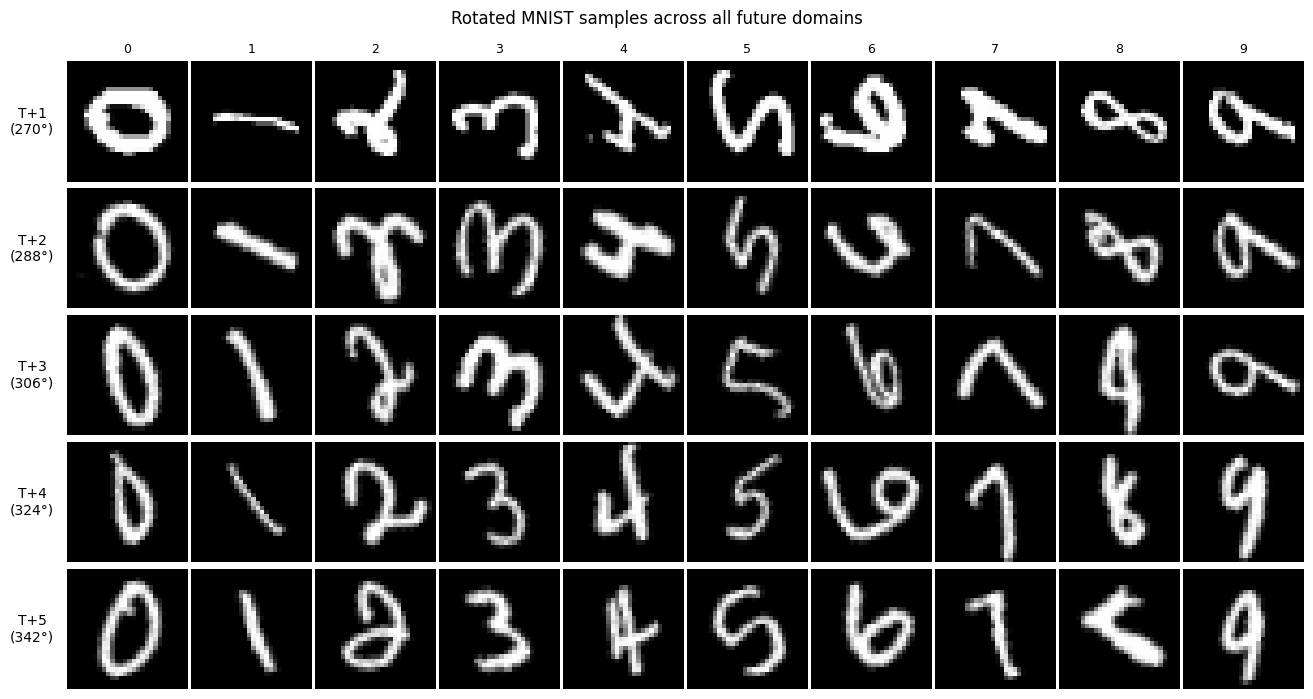

In [7]:
selected_indices = {}
for t in future:
    selected_indices[t] = [int(torch.where(domain_y[t] == label)[0][0]) for label in range(NUM_CLASSES)]

figure, axes = plt.subplots(N_TEST, NUM_CLASSES, figsize=(13, 6.8))
for row, t in enumerate(future):
    for label, index in enumerate(selected_indices[t]):
        axis = axes[row, label]
        axis.imshow(domain_x[t][index, 0], cmap="gray", vmin=0, vmax=1)
        if row == 0:
            axis.set_title(str(label), fontsize=9)
        if label == 0:
            axis.set_ylabel(f"T+{row + 1}\n({domain_angles[t]:.0f}°)", rotation=0, labelpad=25, va="center")
        axis.set_xticks([])
        axis.set_yticks([])
        for spine in axis.spines.values():
            spine.set_visible(False)
figure.suptitle("Rotated MNIST samples across all future domains", y=1.01)
figure.tight_layout(pad=0.25)
plt.show()

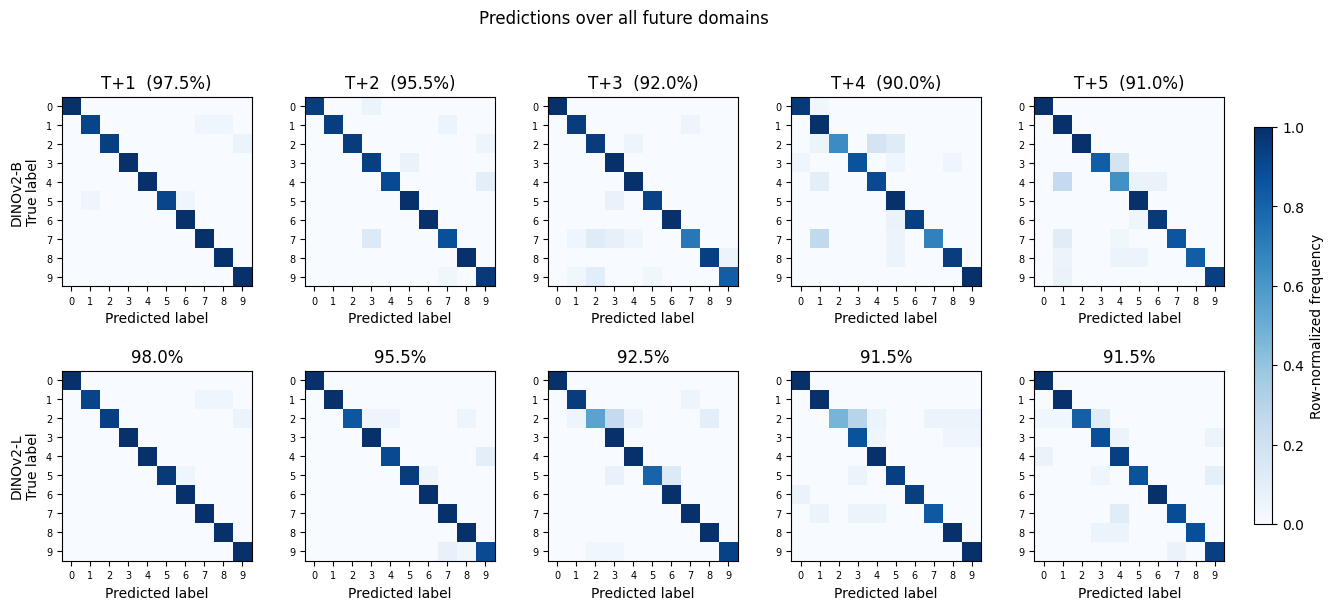

In [8]:
figure, axes = plt.subplots(len(BACKBONES), N_TEST, figsize=(15, 3.1 * len(BACKBONES)), squeeze=False)
for row, backbone in enumerate(BACKBONES):
    for column, t in enumerate(future):
        axis = axes[row, column]
        image = axis.imshow(confusion_matrices[backbone][t], cmap="Blues", vmin=0, vmax=1)
        accuracy = 100 * results[backbone]["future_accuracy"][str(t)]
        if row == 0:
            axis.set_title(f"T+{column + 1}  ({accuracy:.1f}%)")
        else:
            axis.set_title(f"{accuracy:.1f}%")
        if column == 0:
            axis.set_ylabel(f"{CFG[backbone]['name']}\nTrue label")
        axis.set_xlabel("Predicted label")
        axis.set_xticks(range(NUM_CLASSES))
        axis.set_yticks(range(NUM_CLASSES))
        axis.tick_params(labelsize=7)
figure.subplots_adjust(wspace=0.28, hspace=0.35, right=0.90)
colorbar_axis = figure.add_axes([0.92, 0.18, 0.012, 0.64])
colorbar = figure.colorbar(image, cax=colorbar_axis)
colorbar.set_label("Row-normalized frequency")
figure.suptitle("Predictions over all future domains", y=1.01)
plt.show()

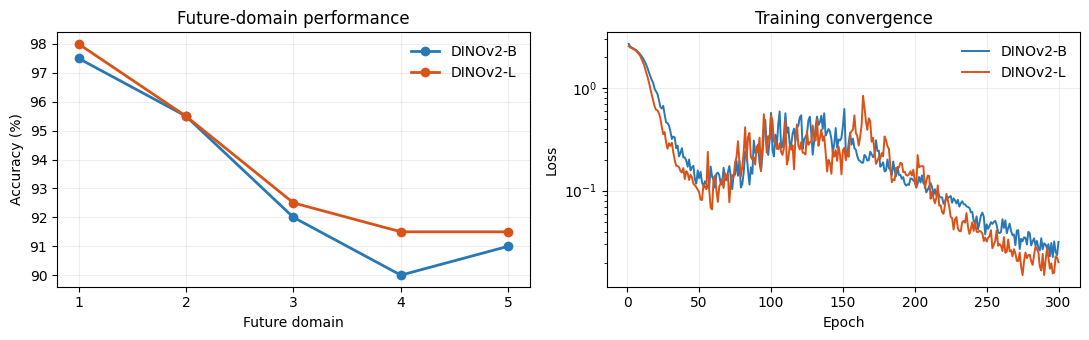

In [9]:
colors = ["#2878B5", "#D95319"]
figure, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for color, backbone in zip(colors, BACKBONES):
    record = results[backbone]
    steps = np.arange(1, N_TEST + 1)
    values = [100 * record["future_accuracy"][str(N_TRAIN + index)] for index in range(N_TEST)]
    axes[0].plot(steps, values, marker="o", linewidth=2, label=record["backbone"], color=color)
    epochs = np.arange(1, len(record["loss_history"]) + 1)
    axes[1].plot(epochs, record["loss_history"], linewidth=1.4, label=record["backbone"], color=color)
axes[0].set(title="Future-domain performance", xlabel="Future domain", ylabel="Accuracy (%)", xticks=steps)
axes[1].set(title="Training convergence", xlabel="Epoch", ylabel="Loss", yscale="log")
for axis in axes:
    axis.grid(alpha=0.22)
    axis.legend(frameon=False)
figure.tight_layout()
plt.show()